# Setup and annotation loading

In [2]:
from pathlib import Path
from collections import Counter, defaultdict

import ijson
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_DIR = Path.cwd().parent

ANNOTATION_DIR = PROJECT_DIR / "dataset" / "annotations"

TRAIN_JSON = ANNOTATION_DIR / "bdd100k_labels_images_train.json"
VAL_JSON = ANNOTATION_DIR / "bdd100k_labels_images_val.json"

# Separate bounding-box and polygon annotations

In [3]:
# box2d: rectangular bounding boxes used for object detection.
# poly2d: polygon or line annotations, such as lanes and drivable areas.

def analyse_annotation_types(json_path):

    annotation_types = Counter()
    category_types = defaultdict(Counter)

    with open(json_path, "rb") as file:

        for record in ijson.items(file, "item"):

            for obj in record.get("labels", []):

                category = obj.get("category", "unknown")

                if obj.get("box2d") is not None:
                    annotation_types["box2d"] += 1
                    category_types[category]["box2d"] += 1

                elif obj.get("poly2d") is not None:
                    annotation_types["poly2d"] += 1
                    category_types[category]["poly2d"] += 1

                else:
                    annotation_types["other"] += 1
                    category_types[category]["other"] += 1

    return annotation_types, category_types


train_types, train_category_types = analyse_annotation_types(TRAIN_JSON)
val_types, val_category_types = analyse_annotation_types(VAL_JSON)

print("TRAINING ANNOTATION TYPES")
print(train_types)

print("\nVALIDATION ANNOTATION TYPES")
print(val_types)

TRAINING ANNOTATION TYPES
Counter({'box2d': 1286871, 'poly2d': 654366})

VALIDATION ANNOTATION TYPES
Counter({'box2d': 185526, 'poly2d': 93711})


In [4]:
type_rows = []

for category, counts in train_category_types.items():

    type_rows.append({
        "Category": category,
        "Bounding Boxes": counts["box2d"],
        "Polygons": counts["poly2d"],
        "Other": counts["other"]
    })

type_df = pd.DataFrame(type_rows)

type_df = type_df.sort_values(
    "Bounding Boxes",
    ascending=False
)

type_df

,Category,Bounding Boxes,Polygons,Other
2,car,713211,0,0
1,traffic sign,239686,0,0
0,traffic light,186117,0,0
5,person,91349,0,0
7,truck,29971,0,0
6,bus,11672,0,0
9,bike,7210,0,0
8,rider,4517,0,0
10,motor,3002,0,0
11,train,136,0,0


# Detection-only class distribution(box2d)

In [5]:
def get_detection_statistics(json_path):

    instance_counts = Counter()
    image_counts = Counter()

    total_images = 0
    images_with_boxes = 0

    with open(json_path, "rb") as file:

        for record in ijson.items(file, "item"):

            total_images += 1
            image_categories = set()

            for obj in record.get("labels", []):

                box = obj.get("box2d")

                if not box:
                    continue

                category = obj.get("category")

                if not category:
                    continue

                instance_counts[category] += 1
                image_categories.add(category)

            if image_categories:
                images_with_boxes += 1

            for category in image_categories:
                image_counts[category] += 1

    return instance_counts, image_counts, total_images, images_with_boxes


train_instances, train_images, train_total, train_box_images = (
    get_detection_statistics(TRAIN_JSON)
)

val_instances, val_images, val_total, val_box_images = (
    get_detection_statistics(VAL_JSON)
)

print("Training images:", train_total)
print("Training images with boxes:", train_box_images)

print("\nValidation images:", val_total)
print("Validation images with boxes:", val_box_images)

Training images: 69863
Training images with boxes: 69863

Validation images: 10000
Validation images with boxes: 10000


In [6]:
all_categories = sorted(
    set(train_instances) | set(val_instances)
)

detection_df = pd.DataFrame([
    {
        "Category": category,
        "Train Instances": train_instances[category],
        "Train Images": train_images[category],
        "Validation Instances": val_instances[category],
        "Validation Images": val_images[category]
    }
    for category in all_categories
])

detection_df = detection_df.sort_values(
    "Train Instances",
    ascending=False
).reset_index(drop=True)

detection_df

,Category,Train Instances,Train Images,Validation Instances,Validation Images
0,car,713211,69072,102506,9879
1,traffic sign,239686,57154,34908,8221
2,traffic light,186117,39237,26885,5653
3,person,91349,22076,13262,3220
4,truck,29971,18890,4245,2689
5,bus,11672,8993,1597,1242
6,bike,7210,4343,1007,578
7,rider,4517,3586,649,515
8,motor,3002,2284,452,334
9,train,136,105,15,14


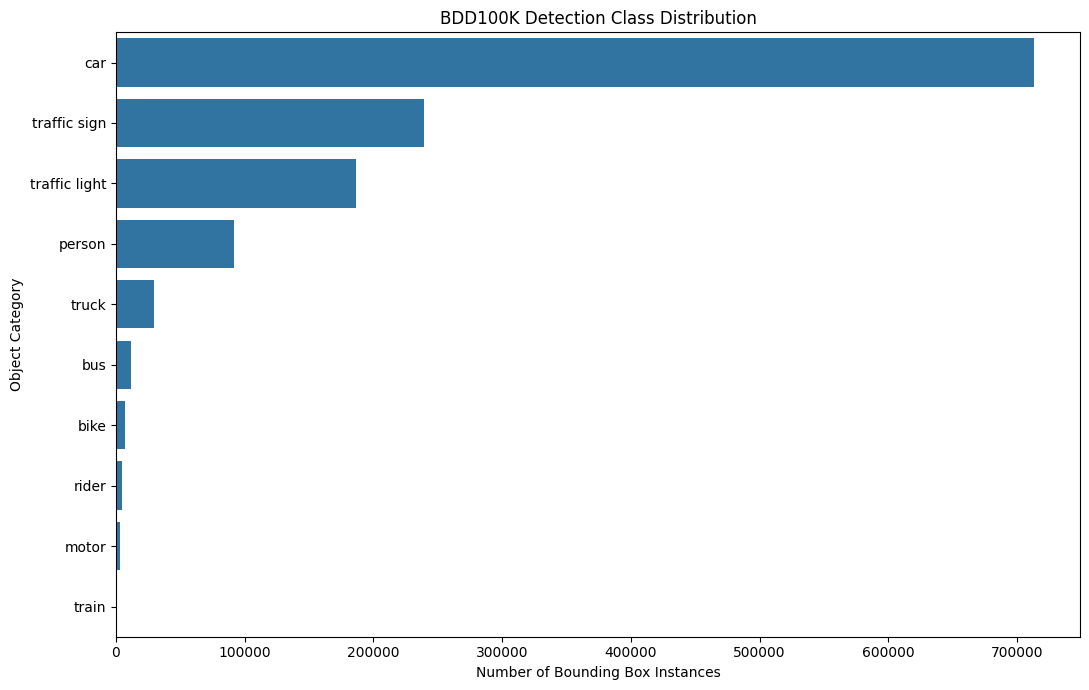

In [7]:
plt.figure(figsize=(11, 7))

sns.barplot(
    data=detection_df,
    x="Train Instances",
    y="Category"
)

plt.title("BDD100K Detection Class Distribution")
plt.xlabel("Number of Bounding Box Instances")
plt.ylabel("Object Category")
plt.tight_layout()
plt.show()

# Class imbalance analysis

In [8]:
total_instances = detection_df["Train Instances"].sum()

detection_df["Percentage"] = (
    detection_df["Train Instances"] / total_instances * 100
)

detection_df["Percentage"] = detection_df["Percentage"].round(3)

detection_df[[
    "Category",
    "Train Instances",
    "Percentage"
]]

,Category,Train Instances,Percentage
0,car,713211,55.422
1,traffic sign,239686,18.625
2,traffic light,186117,14.463
3,person,91349,7.099
4,truck,29971,2.329
5,bus,11672,0.907
6,bike,7210,0.560
7,rider,4517,0.351
8,motor,3002,0.233
9,train,136,0.011


# Analyse occlusion and truncation
- occluded: whether an object is partially hidden.
- truncated: whether an object extends beyond the image boundary.

In [9]:
attribute_counts = {
    "occluded": Counter(),
    "truncated": Counter()
}

with open(TRAIN_JSON, "rb") as file:

    for record in ijson.items(file, "item"):

        for obj in record.get("labels", []):

            if not obj.get("box2d"):
                continue

            attributes = obj.get("attributes", {})

            for attribute in attribute_counts:

                value = attributes.get(attribute)

                if value is not None:
                    attribute_counts[attribute][value] += 1


for attribute, counts in attribute_counts.items():

    print(f"\n{attribute.upper()}")

    for value, count in counts.items():
        print(f"{value}: {count:,}")


OCCLUDED
False: 678,142
True: 608,729

TRUNCATED
False: 1,197,683
True: 89,188


In [10]:
CLASS_NAMES = [
    "car",
    "traffic sign",
    "traffic light",
    "person",
    "truck",
    "bus",
    "bike",
    "rider",
    "motor",
    "train"
]

CLASS_MAPPING = {
    name: class_id
    for class_id, name in enumerate(CLASS_NAMES)
}

NUM_CLASSES = len(CLASS_NAMES)

print("Number of classes:", NUM_CLASSES)

for class_id, name in enumerate(CLASS_NAMES):
    print(f"{class_id}: {name}")

Number of classes: 10
0: car
1: traffic sign
2: traffic light
3: person
4: truck
5: bus
6: bike
7: rider
8: motor
9: train


# 7. Conclusion

## Final Dataset Decisions

- Total training images: 69,863
- Total validation images: 10,000
- Detection categories: 10
- Polygon annotations excluded: lane, drivable area
- All 10 bounding-box categories retained.
- Occluded and truncated objects retained.
- Original class imbalance preserved.

## Final Decision

We will initially train YOLO11n using the original
class distribution and standard data augmentation.

We will evaluate individual class performance and
consider targeted class balancing only if required.
